<a href="https://colab.research.google.com/github/Stellamatt0303/FINTECH-P2-MATTEUCCI-CHERVENKA-/blob/main/FINA4075_P2_October_Checkpoint_2_StrategyLab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FINA 4075/5075 — Project 2 Checkpoint 2 Notebook

**Before running anything:** File → **Save a copy in Drive**, then Runtime → Change runtime type → **Runtime version 2026.07** (Rule 0).

Follow the Project 2 Detailed Student Instructions (D2L). Run cells top to bottom; finish with **Runtime → Restart session and run all** — it must complete with no errors before you submit.

In [8]:
# Cell 1 — mount Drive (Rule 1)
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [9]:
# Cell 2 — create the course folder
import os
P0 = "/content/drive/MyDrive/FINA4075/P2"
os.makedirs(P0, exist_ok=True)
print("Folder ready:", P0)

Folder ready: /content/drive/MyDrive/FINA4075/P2


In [10]:
# Cell 3 — pinned setup (Rule 2; -q omitted in P0 on purpose)
# Official pinned line (Fall 2026), as posted in D2L (Rule 2).
%pip install yfinance==0.2.66

In [11]:
# Cell 4 — environment stamp (Rule 0)
import sys, pandas as pd, numpy as np, matplotlib, yfinance as yf
print(sys.version)
print("pandas", pd.__version__, "| numpy", np.__version__,
      "| matplotlib", matplotlib.__version__, "| yfinance", yf.__version__)

3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
pandas 2.2.3 | numpy 2.4.6 | matplotlib 3.10.0 | yfinance 0.2.66


### Project 2 Setup & File Verification

In [12]:
# Project 2 — locate the required files
from pathlib import Path

P2_DIR = Path("/content/drive/MyDrive/FINA4075/P2")

panel_path = P2_DIR / "panel_returns_2026-10-31.csv"
ticker_path = P2_DIR / "P2_ticker_list_2026-08-31.csv"

print("Project 2 folder:", P2_DIR)
print("Panel exists:", panel_path.exists())
print("Ticker list exists:", ticker_path.exists())

assert panel_path.exists(), f"Panel file not found: {panel_path}"
assert ticker_path.exists(), f"Ticker-list file not found: {ticker_path}"

Project 2 folder: /content/drive/MyDrive/FINA4075/P2
Panel exists: True
Ticker list exists: True


In [13]:
# Project 2 — load and validate the panel
panel = pd.read_csv(panel_path, index_col=0)

print("Panel shape:", panel.shape)

assert panel.shape == (94, 200), (
    f"Expected panel shape (94, 200), but received {panel.shape}"
)

display(panel.head())

Panel shape: (94, 200)


,NYT,MTCH,SIRI,MSGS,SNAP,LUMN,TTD,NXST,IRDM,TDS,...,NJR,OGS,SR,NWE,OTTR,AWR,CPK,AVA,CWT,MGEE
date,,,,,,,,,,,,,,,,,,,,,
2019-01-31,0.155454,0.250643,0.021016,0.038102,0.212341,0.011222,0.229364,0.061420,0.050406,0.113092,...,0.061967,0.032036,0.071409,0.075201,-0.023973,0.010143,0.114022,-0.014830,0.039026,0.072548
2019-02-28,0.277713,0.035334,0.019229,0.036848,0.467066,-0.139035,0.384497,0.177107,0.098556,-0.115130,...,-0.002062,0.058599,-0.000630,0.072446,0.045157,0.054536,-0.006183,-0.025312,0.054622,-0.000805
2019-03-29,0.000000,0.022210,-0.043845,0.017318,0.124490,-0.072118,0.002076,0.108872,0.241897,-0.036221,...,0.034735,0.029844,0.045251,0.035713,-0.009149,0.002391,0.017360,0.005197,0.043444,0.063361
2019-04-30,0.010640,0.066949,0.024691,0.065875,0.010889,-0.047540,0.118868,0.080096,0.038578,0.037423,...,0.005824,-0.005728,0.023089,-0.007954,0.029707,-0.001824,0.015678,0.062038,-0.071665,-0.002648
2019-05-31,-0.040121,0.136589,-0.084144,-0.053130,0.067325,-0.063047,-0.102357,-0.140814,-0.219592,-0.096298,...,-0.052516,-0.005223,-0.010334,0.015605,-0.025094,0.028772,-0.020077,-0.022931,-0.019313,-0.017895


In [14]:
# Project 2 — calculate and verify the panel SHA-256
from pathlib import Path
import hashlib

# Define the file location
P2_DIR = Path("/content/drive/MyDrive/FINA4075/P2")
panel_path = P2_DIR / "panel_returns_2026-10-31.csv"

# Confirm the file exists
assert panel_path.exists(), f"Panel file not found: {panel_path}"

def sha256_file(file_path):
    sha = hashlib.sha256()

    with open(file_path, "rb") as file:
        for block in iter(lambda: file.read(1024 * 1024), b""):
            sha.update(block)

    return sha.hexdigest()

actual_hash = sha256_file(panel_path)
expected_hash = "f4732d3f86648720cb7de55cb7139ab788da8cd7872da9cad11420a5eac5da27"

print("Actual SHA-256:  ", actual_hash)
print("Expected SHA-256:", expected_hash)

assert actual_hash.lower() == expected_hash.lower(), (
    "SHA-256 does not match the Data Dictionary."
)

print("SHA-256 verified successfully.")

Actual SHA-256:   f4732d3f86648720cb7de55cb7139ab788da8cd7872da9cad11420a5eac5da27
Expected SHA-256: f4732d3f86648720cb7de55cb7139ab788da8cd7872da9cad11420a5eac5da27
SHA-256 verified successfully.


In [15]:
# Pre-commit exploration — load company information
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

P2_DIR = Path("/content/drive/MyDrive/FINA4075/P2")
companies = pd.read_csv(ticker_path)

# Work with a separate copy; do not change the original CSV
explore_returns = panel.copy()
explore_returns.index = pd.to_datetime(explore_returns.index)
explore_returns = explore_returns.sort_index()
explore_returns.columns = explore_returns.columns.str.strip()

companies["Ticker"] = companies["Ticker"].str.strip()
assert companies["Ticker"].is_unique, "Duplicate tickers in company list."

company_info = companies.set_index("Ticker")

missing_tickers = explore_returns.columns.difference(company_info.index)
assert len(missing_tickers) == 0, f"Unmatched tickers: {missing_tickers.tolist()}"

print("Company list loaded:", len(companies), "companies")
print("Sectors:", companies["Sector"].nunique())
print("Missing return values:", explore_returns.isna().sum().sum())

display(companies[["Ticker", "Company", "Sector"]].head())

Company list loaded: 200 companies
Sectors: 11
Missing return values: 0


,Ticker,Company,Sector
0,NYT,The New York Times Company,Communication Services
1,MTCH,"Match Group, Inc.",Communication Services
2,SIRI,Sirius XM Holdings Inc.,Communication Services
3,MSGS,Madison Square Garden Sports Corp.,Communication Services
4,SNAP,Snap Inc.,Communication Services


In [16]:
# Historical summary statistics for all 200 stocks
stock_summary = pd.DataFrame({
    "Mean monthly return": explore_returns.mean(),
    "Monthly volatility": explore_returns.std(ddof=1),
    "Worst month": explore_returns.min(),
    "Best month": explore_returns.max(),
    "Months available": explore_returns.count()
})

stock_summary = stock_summary.join(company_info[["Company", "Sector"]])

display(
    stock_summary.head(10).style.format({
        "Mean monthly return": "{:.2%}",
        "Monthly volatility": "{:.2%}",
        "Worst month": "{:.2%}",
        "Best month": "{:.2%}"
    })
)

print("Summary across the 200 stocks:")
display(stock_summary.iloc[:, :5].describe().round(4))

,Mean monthly return,Monthly volatility,Worst month,Best month,Months available,Company,Sector
NYT,1.76%,9.70%,-19.11%,27.77%,94,The New York Times Company,Communication Services
MTCH,0.67%,11.52%,-27.21%,30.44%,94,"Match Group, Inc.",Communication Services
SIRI,-0.03%,9.52%,-28.12%,27.25%,94,Sirius XM Holdings Inc.,Communication Services
MSGS,1.19%,7.91%,-21.06%,19.97%,94,Madison Square Garden Sports Corp.,Communication Services
SNAP,1.64%,18.26%,-50.42%,50.86%,94,Snap Inc.,Communication Services
LUMN,1.53%,26.49%,-35.24%,186.36%,94,"Lumen Technologies, Inc.",Communication Services
TTD,1.67%,18.35%,-40.75%,59.07%,94,"The Trade Desk, Inc.",Communication Services
NXST,1.76%,11.10%,-49.79%,28.61%,94,"Nexstar Media Group, Inc.",Communication Services
IRDM,1.79%,12.55%,-29.25%,40.84%,94,Iridium Communications Inc.,Communication Services
TDS,1.76%,21.02%,-38.00%,167.96%,94,"Telephone and Data Systems, Inc.",Communication Services


Summary across the 200 stocks:


,Mean monthly return,Monthly volatility,Worst month,Best month,Months available
count,200.0000,200.0000,200.0000,200.0000,200.0
mean,0.0149,0.1130,-0.3065,0.4052,94.0
std,0.0095,0.0458,0.1425,0.3222,0.0
min,-0.0003,0.0540,-0.8143,0.1179,94.0
25%,0.0086,0.0797,-0.3819,0.2231,94.0
50%,0.0135,0.1029,-0.2831,0.3087,94.0
75%,0.0183,0.1312,-0.1891,0.4426,94.0
max,0.0556,0.3528,-0.1099,2.3396,94.0


In [17]:
# Signal for each portfolio month:
# standard deviation of the previous 36 months, excluding that month
low_vol_signal = (
    explore_returns.shift(1)
    .rolling(window=36, min_periods=36)
    .std(ddof=1)
)

portfolio_month = explore_returns.index[-1]
latest_signal = low_vol_signal.iloc[-1].dropna()

assert len(latest_signal) >= 20, "Not enough stocks with 36 months of data."

ranking = latest_signal.rename("Monthly volatility").to_frame()
ranking.index.name = "Ticker"
ranking = ranking.reset_index()

# Lowest volatility first; alphabetical ticker breaks ties
ranking = ranking.sort_values(
    ["Monthly volatility", "Ticker"],
    ascending=[True, True]
)

selected20 = (
    ranking.head(20)
    .set_index("Ticker")
    .join(company_info[["Company", "Sector"]])
)

selected20["Annualized volatility"] = (
    selected20["Monthly volatility"] * np.sqrt(12)
)
selected20["Weight"] = 1 / 20

print("Illustrative portfolio month:", portfolio_month.strftime("%B %Y"))
print(
    "Signal uses:",
    explore_returns.index[-37].strftime("%B %Y"),
    "through",
    explore_returns.index[-2].strftime("%B %Y")
)

display(selected20.style.format({
    "Monthly volatility": "{:.2%}",
    "Annualized volatility": "{:.2%}",
    "Weight": "{:.0%}"
}))

Illustrative portfolio month: October 2026
Signal uses: October 2023 through September 2026


,Monthly volatility,Company,Sector,Annualized volatility,Weight
Ticker,,,,,
AWR,4.36%,American States Water Company,Utilities,15.09%,5%
OGE,4.48%,OGE Energy Corp.,Utilities,15.51%,5%
POR,4.85%,Portland General Electric Company,Utilities,16.81%,5%
NWE,4.96%,"NorthWestern Energy Group, Inc.",Utilities,17.17%,5%
IDA,4.99%,"IDACORP, Inc.",Utilities,17.30%,5%
ADC,5.00%,Agree Realty Corporation,Real Estate,17.32%,5%
KRG,5.03%,Kite Realty Group Trust,Real Estate,17.43%,5%
AVA,5.13%,Avista Corporation,Utilities,17.75%,5%
NJR,5.16%,New Jersey Resources Corporation,Utilities,17.86%,5%


,Panel stocks,Selected stocks,Panel weight,Selected weight
Sector,,,,
Communication Services,18,1,9.0%,5%
Consumer Discretionary,18,0,9.0%,0%
Consumer Staples,18,1,9.0%,5%
Energy,18,0,9.0%,0%
Financials,19,0,9.5%,0%
Health Care,18,0,9.0%,0%
Industrials,19,0,9.5%,0%
Information Technology,18,0,9.0%,0%
Materials,18,0,9.0%,0%


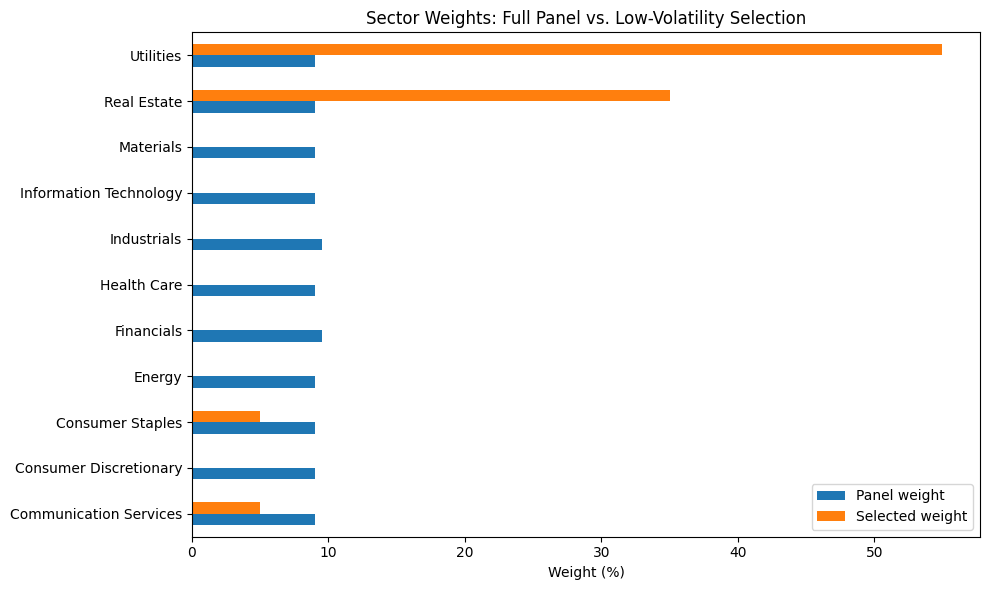

In [18]:
# Compare selected portfolio weights with full-panel sector weights
full_sector_counts = (
    company_info.loc[explore_returns.columns, "Sector"]
    .value_counts()
)

selected_sector_counts = selected20["Sector"].value_counts()

sector_comparison = pd.DataFrame({
    "Panel stocks": full_sector_counts,
    "Selected stocks": selected_sector_counts
}).fillna(0).astype(int).sort_index()

sector_comparison["Panel weight"] = (
    sector_comparison["Panel stocks"] / explore_returns.shape[1]
)
sector_comparison["Selected weight"] = (
    sector_comparison["Selected stocks"] / 20
)

display(sector_comparison.style.format({
    "Panel weight": "{:.1%}",
    "Selected weight": "{:.0%}"
}))

# Display weights as percentages
ax = (
    sector_comparison[["Panel weight", "Selected weight"]] * 100
).plot.barh(figsize=(10, 6))

ax.set_title("Sector Weights: Full Panel vs. Low-Volatility Selection")
ax.set_xlabel("Weight (%)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

Runtime - Restart session and run all - Confirm the panel shape is (94, 200) and the SHA-256 verification succeeds.


## Locked Strategy and In-Sample Backtest

The cells below implement the locked 36-month low-volatility rule and produce
the required January 2022–August 2026 backtest exhibit.


In [19]:
"""
strategy.py — LOCKED STRATEGY CODE (Track 1)
FINA 4075/5075 Project 2 — Fall 2026

Rule (strategy_rules.md governs if the two ever disagree):
  For portfolio month t, calculate each eligible stock's sample standard
  deviation over the 36 monthly total returns t-36 through t-1, with ddof=1
  and no skip-month. Rank ascending, breaking exact ties alphabetically by
  ticker. Hold the 20 lowest-volatility stocks at equal weights, rebalance
  monthly, and charge 10 basis points per side.

CODE RULE: after the pre-registration commit, rerun this file unchanged at
each checkpoint. Do not edit it in response to backtest or live results.
"""

import numpy as np
import pandas as pd


PER_SIDE = 0.0010
N_HOLD = 20
WINDOW = 36
FIRST_TRADEABLE = WINDOW       # row 36 = January 2022


def load_panel(panel_path, ticker_path):
    """Read the course files and return (rets, dates, tickers, info).

    rets: T x N NumPy array of simple monthly total returns.
    dates: month-end dates from the panel.
    tickers: ticker symbols in panel-column order.
    info: instructor ticker-list data indexed by Ticker.
    """
    panel = pd.read_csv(panel_path, index_col=0, parse_dates=True)
    info = pd.read_csv(ticker_path).set_index("Ticker")

    panel.columns = panel.columns.astype(str).str.strip()
    info.index = info.index.astype(str).str.strip()
    panel = panel.apply(pd.to_numeric, errors="raise")

    tickers = list(panel.columns)
    assert list(info.index) == tickers, "ticker list and panel columns differ"
    assert panel.index.is_monotonic_increasing, "panel dates are not chronological"
    assert panel.index.is_unique, "panel contains duplicate dates"
    assert len(tickers) == len(set(tickers)), "panel contains duplicate tickers"
    assert not np.isinf(panel.to_numpy()).any(), "panel contains infinite returns"

    return panel.to_numpy(dtype=float), panel.index, tickers, info


def signal(t, rets):
    """Sample volatility over rows t-36 through t-1 inclusive."""
    window = rets[t - WINDOW:t]
    assert window.shape[0] == WINDOW
    return np.std(window, axis=0, ddof=1)


def select_holdings(t, rets, tickers):
    """Return indices of the 20 eligible stocks with lowest volatility.

    A stock is ineligible if any return in its 36-month signal window is
    missing. Exact volatility ties are broken alphabetically by ticker.
    """
    if t < FIRST_TRADEABLE:
        raise ValueError("36 months of history are required before selection")

    window = rets[t - WINDOW:t]
    eligible = np.isfinite(window).all(axis=0)
    vol = signal(t, rets)

    candidates = [i for i in range(len(tickers)) if eligible[i]]
    if len(candidates) < N_HOLD:
        raise ValueError("fewer than 20 stocks have complete 36-month histories")

    order = sorted(candidates, key=lambda i: (vol[i], tickers[i]))
    return set(order[:N_HOLD])


def run_track(select_fn, rets, t0, t1, per_side=PER_SIDE):
    """Run a strategy from row t0 through row t1, inclusive.

    Equal weights; first month turnover = 1; later one-way turnover equals
    names entering divided by 20; monthly cost = 2 * per_side * turnover.
    Returns (values, turnovers, holdings), where values starts at 1.0.
    """
    if not (0 <= t0 <= t1 < len(rets)):
        raise ValueError("invalid backtest row range")

    previous = set()
    values = [1.0]
    turnovers = []
    holdings = []

    for t in range(t0, t1 + 1):
        current = select_fn(t, rets)
        if len(current) != N_HOLD:
            raise ValueError("selection rule must return exactly 20 holdings")

        turnover = 1.0 if not previous else len(current - previous) / N_HOLD
        gross_return = rets[t, sorted(current)].mean()
        cost = 2 * per_side * turnover
        net_return = gross_return - cost

        values.append(values[-1] * (1 + net_return))
        turnovers.append(turnover)
        holdings.append(current)
        previous = current

    return np.array(values), np.array(turnovers), holdings


def bench(rets, t0, t1):
    """Equal-weighted full-panel benchmark, monthly rebalanced, no costs."""
    if not (0 <= t0 <= t1 < len(rets)):
        raise ValueError("invalid benchmark row range")

    values = [1.0]
    for t in range(t0, t1 + 1):
        active = np.isfinite(rets[t])
        if not active.any():
            raise ValueError(f"no active benchmark stocks in row {t}")
        monthly_return = rets[t, active].mean()
        values.append(values[-1] * (1 + monthly_return))
    return np.array(values)


def stats(values, turns=None):
    """Calculate the performance measures required by the assignment."""
    values = np.asarray(values, dtype=float)
    months = len(values) - 1
    if months < 2:
        raise ValueError("at least two return months are required for statistics")

    monthly = values[1:] / values[:-1] - 1
    cagr = (values[-1] / values[0]) ** (12 / months) - 1
    vol = monthly.std(ddof=1) * np.sqrt(12)
    sharpe = cagr / vol if vol != 0 else np.nan
    maxdd = (values / np.maximum.accumulate(values) - 1).min()

    output = {
        "CAGR": cagr,
        "Annualized volatility": vol,
        "Sharpe (rf = 0)": sharpe,
        "Maximum drawdown": maxdd,
        "Growth of $10,000": 10000 * values[-1],
    }

    if turns is not None:
        turns = np.asarray(turns, dtype=float)
        if len(turns) != months:
            raise ValueError("turnover count must equal return-month count")
        output["Annual one-way turnover"] = turns.mean() * 12
        output["Cost drag per year"] = 2 * PER_SIDE * turns.mean() * 12

    return output


def run_low_volatility_backtest(rets, tickers):
    """Convenience wrapper for January 2022 through the panel's final month."""
    if len(rets) <= FIRST_TRADEABLE:
        raise ValueError("panel does not contain a tradeable month")

    select_fn = lambda t, data: select_holdings(t, data, tickers)
    t0 = FIRST_TRADEABLE
    t1 = len(rets) - 1

    strategy_values, turnovers, holdings = run_track(
        select_fn, rets, t0, t1
    )
    benchmark_values = bench(rets, t0, t1)

    return strategy_values, benchmark_values, turnovers, holdings, t0, t1


In [20]:

# Use the already verified panel and company information
panel_for_backtest = panel.iloc[:92].copy()
panel_for_backtest.index = pd.to_datetime(panel_for_backtest.index)
panel_for_backtest = panel_for_backtest.sort_index()

rets = panel_for_backtest.to_numpy(dtype=float)
dates = panel_for_backtest.index
tickers = list(panel_for_backtest.columns)
info = company_info.copy()

assert rets.shape == (92, 200)
assert len(tickers) == len(set(tickers)) == 200
print("Backtest inputs ready:", rets.shape)


Backtest inputs ready: (92, 200)


In [21]:

# Run the locked rule from January 2022 through August 2026
strategy_values, benchmark_values, turnovers, holdings, t0, t1 = (
    run_low_volatility_backtest(rets, tickers)
)

assert len(strategy_values) - 1 == 56
assert dates[t0].to_period("M") == pd.Period("2022-01")
assert dates[t1].to_period("M") == pd.Period("2026-08")
assert all(len(month_holdings) == 20 for month_holdings in holdings)

print("Backtest months:", len(strategy_values) - 1)
print("First month:", dates[t0].date())
print("Last month:", dates[t1].date())


Backtest months: 56
First month: 2022-01-31
Last month: 2026-08-31


In [22]:

# Required performance statistics
strategy_stats = stats(strategy_values, turnovers)
benchmark_stats = stats(benchmark_values)

stats_table = pd.DataFrame({
    "Measure": [
        "CAGR",
        "Annualized volatility",
        "Sharpe (rf = 0)",
        "Maximum drawdown",
        "Annual one-way turnover",
        "Growth of $10,000",
    ],
    "36-Month Low Volatility — Net": [
        f"{strategy_stats['CAGR']:.2%}",
        f"{strategy_stats['Annualized volatility']:.2%}",
        f"{strategy_stats['Sharpe (rf = 0)']:.3f}",
        f"{strategy_stats['Maximum drawdown']:.2%}",
        f"{strategy_stats['Annual one-way turnover']:.2%}",
        f"${strategy_stats['Growth of $10,000']:,.2f}",
    ],
    "Equal-Weighted Benchmark": [
        f"{benchmark_stats['CAGR']:.2%}",
        f"{benchmark_stats['Annualized volatility']:.2%}",
        f"{benchmark_stats['Sharpe (rf = 0)']:.3f}",
        f"{benchmark_stats['Maximum drawdown']:.2%}",
        "—",
        f"${benchmark_stats['Growth of $10,000']:,.2f}",
    ],
}).set_index("Measure")

display(stats_table)

print(f"Strategy CAGR: {strategy_stats['CAGR']:.2%}")
print(f"Strategy annualized volatility: {strategy_stats['Annualized volatility']:.2%}")
print(f"Strategy Sharpe (rf = 0): {strategy_stats['Sharpe (rf = 0)']:.3f}")
print(f"Strategy maximum drawdown: {strategy_stats['Maximum drawdown']:.2%}")
print(f"Annual one-way turnover: {strategy_stats['Annual one-way turnover']:.2%}")
print(f"Strategy ending value: ${strategy_stats['Growth of $10,000']:,.2f}")
print(f"Benchmark ending value: ${benchmark_stats['Growth of $10,000']:,.2f}")


,36-Month Low Volatility — Net,Equal-Weighted Benchmark
Measure,,
CAGR,3.81%,11.83%
Annualized volatility,13.52%,17.44%
Sharpe (rf = 0),0.281,0.678
Maximum drawdown,-13.50%,-14.81%
Annual one-way turnover,112.50%,—
"Growth of $10,000","$11,903.89","$16,847.44"


Strategy CAGR: 3.81%
Strategy annualized volatility: 13.52%
Strategy Sharpe (rf = 0): 0.281
Strategy maximum drawdown: -13.50%
Annual one-way turnover: 112.50%
Strategy ending value: $11,903.89
Benchmark ending value: $16,847.44


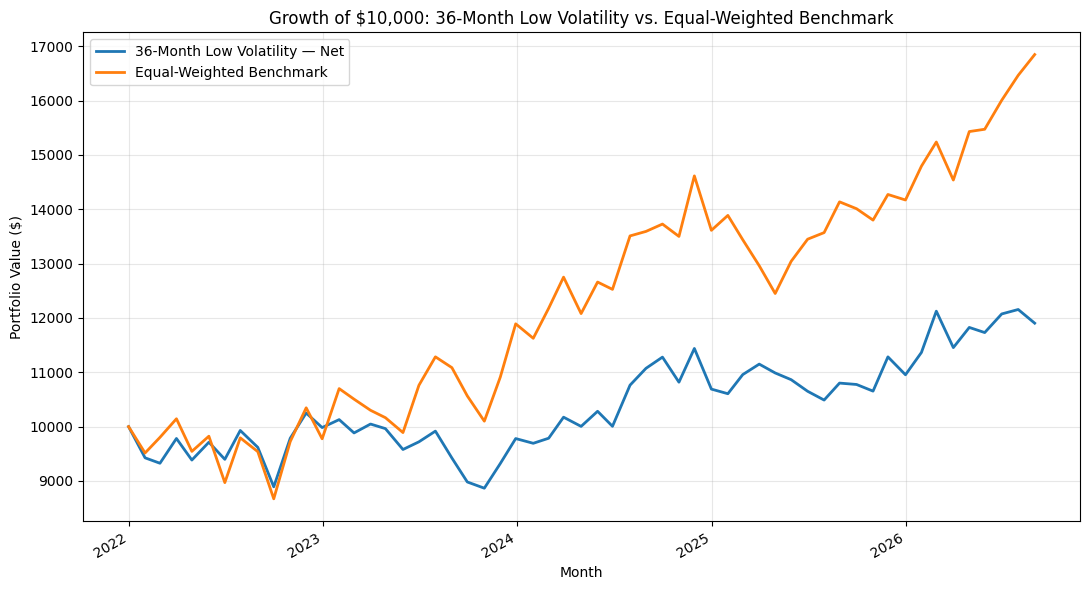

36-Month Low Volatility — Net    $11,903.89
Equal-Weighted Benchmark         $16,847.44
Name: 2026-08-31 00:00:00, dtype: object


In [23]:

# Growth-of-$10,000 exhibit
performance_dates = pd.DatetimeIndex(dates[t0:t1 + 1])
initial_date = performance_dates[0] - pd.offsets.MonthEnd(1)
growth_dates = pd.DatetimeIndex([initial_date, *performance_dates.tolist()])

growth = pd.DataFrame({
    "36-Month Low Volatility — Net": 10000 * strategy_values,
    "Equal-Weighted Benchmark": 10000 * benchmark_values,
}, index=growth_dates)

ax = growth.plot(figsize=(11, 6), linewidth=2)
ax.set_title("Growth of $10,000: 36-Month Low Volatility vs. Equal-Weighted Benchmark")
ax.set_xlabel("Month")
ax.set_ylabel("Portfolio Value ($)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

assert growth.iloc[0].eq(10000).all()
print(growth.iloc[-1].map(lambda value: f"${value:,.2f}"))


In [24]:

# Hand verification — January 2022
month_t = t0
month_holdings = sorted(holdings[0])
three_indices = month_holdings[:3]

hand_check = pd.DataFrame({
    "Ticker": [tickers[i] for i in three_indices],
    "Monthly return": [rets[month_t, i] for i in three_indices],
    "Weight": [0.05] * 3,
})
hand_check["Contribution"] = hand_check["Monthly return"] * hand_check["Weight"]
display(hand_check.style.format({
    "Monthly return": "{:.4%}",
    "Weight": "{:.0%}",
    "Contribution": "{:.4%}",
}))

gross_return = rets[month_t, month_holdings].mean()
transaction_cost = 2 * PER_SIDE * 1.0
net_return = gross_return - transaction_cost
manual_value = 10000 * (1 + net_return)
backtest_value = 10000 * strategy_values[1]

print(f"Gross portfolio return: {gross_return:.6f}")
print(f"Transaction cost: {transaction_cost:.6f}")
print(f"Net portfolio return: {net_return:.6f}")
print(f"Manual ending value: ${manual_value:,.2f}")
print(f"Backtest ending value: ${backtest_value:,.2f}")
assert round(manual_value, 2) == round(backtest_value, 2)
print("Hand-check matches the backtest to the cent.")


,Ticker,Monthly return,Weight,Contribution
0,CPB,2.3772%,5%,0.1189%
1,FDS,-13.1931%,5%,-0.6597%
2,BAH,-9.5058%,5%,-0.4753%


Gross portfolio return: -0.055413
Transaction cost: 0.002000
Net portfolio return: -0.057413
Manual ending value: $9,425.87
Backtest ending value: $9,425.87
Hand-check matches the backtest to the cent.



### In-sample interpretation

The 36-month low-volatility strategy produced lower volatility and a smaller
maximum drawdown than the equal-weighted benchmark, but it also produced a
substantially lower CAGR and Sharpe ratio over the 56-month in-sample window.
These results describe the locked rule's historical arithmetic and do not
establish how it will perform during the live evaluation period.



## Step 8 — Monthly Briefing-Table Generator

This function produces the standardized table as of any available month-end.
The resulting plain-text table is the only input supplied to the frozen LLM
analyst.


In [25]:
panel_df = panel.copy()

# Define P2_DIR for saving files
from pathlib import Path
P2_DIR = Path('/content/drive/MyDrive/FINA4075/P2/')

import pandas as pd
import numpy as np

def generate_briefing_table(panel, company_info, as_of_month):
    """
    Generate the standardized LLM briefing table as of any available month-end.

    Output columns:
    Ticker | Company | Sector | 1M | 3M | 12M
    """

    # Create a separate working copy
    returns = panel.copy()

    # Convert dates to monthly periods and sort chronologically
    returns.index = pd.to_datetime(returns.index).to_period("M")
    returns = returns.sort_index()
    returns.columns = returns.columns.astype(str).str.strip()
    returns = returns.apply(pd.to_numeric, errors="raise")

    # Convert the requested month to a monthly period
    as_of_period = pd.Period(as_of_month, freq="M")

    assert returns.index.is_unique, "Duplicate months found."
    assert returns.columns.is_unique, "Duplicate tickers found."

    if as_of_period not in returns.index:
        raise ValueError(
            f"{as_of_period} is not available in the return panel."
        )

    # Find the row position of the requested month
    month_position = returns.index.get_loc(as_of_period)

    if month_position < 11:
        raise ValueError(
            "At least 12 months of returns are required."
        )

    # Validate that the trailing 12 months are consecutive
    actual_months = returns.index[
        month_position - 11:month_position + 1
    ]

    expected_months = pd.period_range(
        end=as_of_period,
        periods=12,
        freq="M"
    )

    assert actual_months.equals(expected_months), (
        "The trailing 12-month window is not consecutive."
    )

    # Required trailing windows
    window_1m = returns.iloc[
        month_position:month_position + 1
    ]
    window_3m = returns.iloc[
        month_position - 2:month_position + 1
    ]
    window_12m = returns.iloc[
        month_position - 11:month_position + 1
    ]

    # Return NA if any required observation in that window is missing
    ret_1m = window_1m.iloc[0].where(
        window_1m.notna().all(axis=0)
    )

    ret_3m = (
        (1 + window_3m).prod(axis=0) - 1
    ).where(
        window_3m.notna().all(axis=0)
    )

    ret_12m = (
        (1 + window_12m).prod(axis=0) - 1
    ).where(
        window_12m.notna().all(axis=0)
    )

    # Create the return table
    briefing = pd.DataFrame({
        "1M": ret_1m,
        "3M": ret_3m,
        "12M": ret_12m
    })

    briefing.index.name = "Ticker"

    # Prepare company information
    company_data = company_info.copy()
    company_data.index = (
        company_data.index.astype(str).str.strip()
    )

    # Add company name and sector
    briefing = briefing.join(
        company_data[["Company", "Sector"]],
        how="left"
    )

    # Place columns in the required order
    briefing = (
        briefing.reset_index()
        [["Ticker", "Company", "Sector", "1M", "3M", "12M"]]
        .sort_values("Ticker")
        .reset_index(drop=True)
    )

    # Required validation
    assert len(briefing) == returns.shape[1], (
        "Briefing-table row count does not match the panel."
    )
    assert briefing["Ticker"].is_unique, (
        "Duplicate tickers found in briefing table."
    )
    assert briefing["Company"].notna().all(), (
        "One or more companies did not match the company list."
    )
    assert briefing["Sector"].notna().all(), (
        "One or more sectors did not match the company list."
    )

    # Avoid breaking the pipe-delimited format
    assert not briefing["Company"].str.contains(
        "|", regex=False
    ).any(), "A company name contains the | character."

    assert not briefing["Sector"].str.contains(
        "|", regex=False
    ).any(), "A sector contains the | character."

    # Percentage-formatting function
    def format_return(value):
        if pd.isna(value):
            return "NA"
        formatted = f"{100 * value:+.1f}"
        return "+0.0" if formatted == "-0.0" else formatted

    # Create the exact plain-text table supplied to the LLM
    lines = [
        f"BRIEFING TABLE as of {pd.to_datetime(panel.index[month_position]):%Y-%m-%d} (month-end). "
        f"Trailing total returns in percent, dividends reinvested. {len(briefing)} stocks.",
        "Ticker | Company | Sector | 1M | 3M | 12M"
    ]

    for row in briefing.itertuples(index=False):
        lines.append(
            f"{row.Ticker} | "
            f"{row.Company} | "
            f"{row.Sector} | "
            f"{format_return(row[3])} | "
            f"{format_return(row[4])} | "
            f"{format_return(row[5])}"
        )

    briefing_text = "\n".join(lines)

    return briefing, briefing_text


In [26]:
# Generate and validate the October 30, 2026 briefing table
october_briefing, october_briefing_text = generate_briefing_table(
    panel=panel_df,
    company_info=info,
    as_of_month="2026-10",
)

assert len(october_briefing) == 200
assert october_briefing["Ticker"].nunique() == 200
assert list(october_briefing.columns) == [
    "Ticker", "Company", "Sector", "1M", "3M", "12M"
]
assert len(october_briefing_text.splitlines()) - 2 == 200
print(october_briefing_text)
print("October briefing table passed all checks.")


BRIEFING TABLE as of 2026-10-30 (month-end). Trailing total returns in percent, dividends reinvested. 200 stocks.
Ticker | Company | Sector | 1M | 3M | 12M
ACAD | ACADIA Pharmaceuticals Inc. | Health Care | +2.2 | -20.4 | -9.3
ACM | AECOM | Industrials | +8.0 | -12.0 | -52.1
AD | Array Digital Infrastructure, Inc. | Communication Services | -2.6 | -5.7 | +2.0
ADC | Agree Realty Corporation | Real Estate | +0.8 | -12.8 | -4.1
AGCO | AGCO Corporation | Industrials | -2.9 | +8.9 | +8.6
ALK | Alaska Air Group, Inc. | Industrials | -7.7 | -24.7 | -14.4
AMG | Affiliated Managers Group, Inc. | Financials | +4.4 | +4.0 | +60.4
AMRX | Amneal Pharmaceuticals, Inc. | Health Care | +6.8 | +17.4 | +98.8
AOS | A. O. Smith Corporation | Industrials | +12.6 | +5.5 | -2.2
APPF | AppFolio, Inc. | Information Technology | +6.3 | +18.3 | -16.2
AROC | Archrock, Inc. | Energy | +4.7 | -10.8 | +29.0
ASH | Ashland Inc. | Materials | +10.0 | +3.4 | +57.0
AVA | Avista Corporation | Utilities | +7.1 | -5.9 | +3.

In [27]:

# Save the exact October table used for the November analyst run
briefing_output_path = P2_DIR / "briefing_table_2026-10-30.txt"
briefing_output_path.write_text(october_briefing_text, encoding="utf-8")
print("Saved:", briefing_output_path)


Saved: /content/drive/MyDrive/FINA4075/P2/briefing_table_2026-10-30.txt



## Step 9 — September Holdings Verification

Track 1 is generated by the locked code. Track 2 below is the first valid
response from the frozen LLM prompt and is preserved in its original order.


In [28]:

# Track 1 September holdings use September 2023 through August 2026
september_t = len(rets)
track1_indices = select_holdings(september_t, rets, tickers)
track1_september = sorted(tickers[i] for i in track1_indices)

signal_dates = pd.DatetimeIndex(dates[-36:])
assert signal_dates[0].to_period("M") == pd.Period("2023-09")
assert signal_dates[-1].to_period("M") == pd.Period("2026-08")
assert len(track1_september) == len(set(track1_september)) == 20

track2_raw_output = "PBF, DK, OII, PTEN, AMRX, HAE, LNTH, CHEF, PSMT, MSGS, STGW, CNK, ZD, MTRN, ASH, EAT, ETSY, AMG, AVT, SLAB"
track2_september = [ticker.strip() for ticker in track2_raw_output.split(",")]

assert len(track2_september) == len(set(track2_september)) == 20
assert set(track2_september).issubset(set(tickers))

overlap = sorted(set(track1_september) & set(track2_september))

print("Track 1 September holdings:")
print(", ".join(track1_september))
print("\nTrack 2 September holdings, verbatim:")
print(track2_raw_output)
print("\nOverlap:", len(overlap), "of 20")
print(", ".join(overlap) if overlap else "None")


Track 1 September holdings:
ADC, AVA, AWR, BATRK, BKH, BRX, CPB, CTRE, CWT, IDA, INGR, KRG, NJR, NNN, NWE, OGE, OTTR, POR, SR, SWX

Track 2 September holdings, verbatim:
PBF, DK, OII, PTEN, AMRX, HAE, LNTH, CHEF, PSMT, MSGS, STGW, CNK, ZD, MTRN, ASH, EAT, ETSY, AMG, AVT, SLAB

Overlap: 0 of 20
None


In [29]:
# September 2026 performance for both tracks and benchmark
september_returns = panel.loc[
    pd.to_datetime(panel.index).to_period("M") == pd.Period("2026-09")
].iloc[0]

track1_gross = september_returns[track1_september].mean()
track2_gross = september_returns[track2_september].mean()
benchmark_return = september_returns.mean()

# Initial portfolio purchase: 10 basis points per side
initial_cost = 2 * PER_SIDE

print(f"Track 1 September gross return: {track1_gross:.4%}")
print(f"Track 1 September net return: {track1_gross - initial_cost:.4%}")
print(f"Track 2 September gross return: {track2_gross:.4%}")
print(f"Track 2 September net return: {track2_gross - initial_cost:.4%}")
print(f"September benchmark return: {benchmark_return:.4%}")

Track 1 September gross return: -5.2481%
Track 1 September net return: -5.4481%
Track 2 September gross return: -0.6428%
Track 2 September net return: -0.8428%
September benchmark return: -5.7843%


In [30]:
# Select October 2026 holdings using the locked strategy
october_t = panel.index.get_loc("2026-10-30")

october_rets = panel.to_numpy(dtype=float)
october_tickers = list(panel.columns)

october_indices = select_holdings(
    october_t, october_rets, october_tickers
)

track1_october = sorted(
    october_tickers[i] for i in october_indices
)

print("Track 1 October 2026 holdings:")
print(", ".join(track1_october))
print("Number of holdings:", len(track1_october))
standing_october = "ADC, AVA, AWR, BATRK, BKH, BRX, CTRE, CWT, IDA, INGR, KRG, NJR, NNN, NWE, OGE, OTTR, POR, SBRA, SR, STAG"
assert track1_october == standing_october.split(", ")
print("October Track 1 verification: 20 of 20 names match Checkpoint 1.")


Track 1 October 2026 holdings:
ADC, AVA, AWR, BATRK, BKH, BRX, CTRE, CWT, IDA, INGR, KRG, NJR, NNN, NWE, OGE, OTTR, POR, SBRA, SR, STAG
Number of holdings: 20
October Track 1 verification: 20 of 20 names match Checkpoint 1.


In [31]:
# Verify October 2026 portfolio turnover
removed = sorted(set(track1_september) - set(track1_october))
added = sorted(set(track1_october) - set(track1_september))

turnover = len(added) / 20
october_cost = 2 * PER_SIDE * turnover

print("Removed:", ", ".join(removed))
print("Added:", ", ".join(added))
print(f"One-way turnover: {turnover:.2%}")
print(f"October transaction cost: {october_cost:.4%}")

Removed: CPB, SWX
Added: SBRA, STAG
One-way turnover: 10.00%
October transaction cost: 0.0200%


In [32]:
# Record October 2026 Track 2 holdings from the frozen LLM run
track2_october_raw = "AMG, AMRX, AVT, BRKR, CHEF, CNK, GAP, HAE, ITGR, MGNI, MSGS, MUR, NEU, PBF, QLYS, QRVO, RGEN, SAIC, SXT, ZD"

track2_october = [
    ticker.strip() for ticker in track2_october_raw.split(",")
]

assert len(track2_october) == len(set(track2_october)) == 20
assert set(track2_october).issubset(set(tickers))

print("Track 2 October 2026 holdings:")
print(track2_october_raw)
print("Number of holdings:", len(track2_october))

Track 2 October 2026 holdings:
AMG, AMRX, AVT, BRKR, CHEF, CNK, GAP, HAE, ITGR, MGNI, MSGS, MUR, NEU, PBF, QLYS, QRVO, RGEN, SAIC, SXT, ZD
Number of holdings: 20


## Checkpoint 2 October scoring and November holdings

The October return row is held out of the October selection. QRVO's final return is included in October scoring. For November, QRVO exits the investable universe under the written strategy rules. The November analyst reply was recorded on November 7 at 8:41 p.m. Central using GPT-5.6 Instant after GPT-5.6 Sol Light was unavailable in the selector.


In [33]:
# Score standing October portfolios using September holdings for turnover.
october_returns = panel.iloc[october_t]
benchmark_october = october_returns.mean()
assert october_returns.notna().sum() == 200

records = []
portfolios = [
    ("Track 1", track1_september, track1_october),
    ("Track 2", track2_september, track2_october),
    ("Benchmark", tickers, tickers),
]
for label, september_names, october_names in portfolios:
    gross = october_returns[october_names].mean()
    turnover = len(set(october_names) - set(september_names)) / N_HOLD
    cost = 2 * PER_SIDE * turnover
    net = gross - cost
    september_net = september_returns[september_names].mean()
    if label != "Benchmark":
        september_net -= 2 * PER_SIDE
    cumulative = (1 + september_net) * (1 + net) - 1
    records.append((label, gross, turnover, cost, net, net - benchmark_october, cumulative))

results = pd.DataFrame(records, columns=[
    "Portfolio", "Gross return", "One-way turnover", "Cost",
    "Net return", "Gap vs benchmark", "September–October net"
]).set_index("Portfolio")
display(results.style.format("{:+.5%}"))


,Gross return,One-way turnover,Cost,Net return,Gap vs benchmark,September–October net
Portfolio,,,,,,
Track 1,+5.37311%,+10.00000%,+0.02000%,+5.35311%,-0.28593%,-0.38660%
Track 2,+0.51670%,+55.00000%,+0.11000%,+0.40670%,-5.23234%,-0.43953%
Benchmark,+5.63904%,+0.00000%,+0.00000%,+5.63904%,+0.00000%,-0.47148%


In [34]:
# Select November Track 1 holdings and validate the recorded Track 2 reply.
november_t = len(panel)
november_universe = panel.drop(columns="QRVO")
november_tickers = list(november_universe.columns)
november_indices = select_holdings(november_t, november_universe.to_numpy(dtype=float), november_tickers)
track1_november = sorted(november_tickers[i] for i in november_indices)

track2_november_raw = "RRC, HAE, PTEN, STGW, SM, QLYS, CROX, SAIC, R, CVI, MUR, FDS, URBN, MTDR, BKH, TTC, AVNT, KEX, CNK, AMG"
track2_november = track2_november_raw.split(", ")
assert len(track2_november) == len(set(track2_november)) == N_HOLD
assert set(track2_november) <= set(november_tickers)

print("Track 1 November:", ", ".join(track1_november))
print("Track 2 November, verbatim:", track2_november_raw)
for label, previous, current in [
    ("Track 1", track1_october, track1_november),
    ("Track 2", track2_october, track2_november),
]:
    turnover = len(set(current) - set(previous)) / N_HOLD
    print(f"{label} November turnover: {turnover:.0%}; projected cost: {2 * PER_SIDE:.4%} × {turnover:.2f} = {2 * PER_SIDE * turnover:.4%}")
print("November overlap:", ", ".join(sorted(set(track1_november) & set(track2_november))))


Track 1 November: ADC, AVA, AWR, BATRK, BKH, BRX, CPK, CTRE, CWT, IDA, INGR, KRG, NJR, NNN, NWE, OGE, OTTR, POR, SBRA, STAG
Track 2 November, verbatim: RRC, HAE, PTEN, STGW, SM, QLYS, CROX, SAIC, R, CVI, MUR, FDS, URBN, MTDR, BKH, TTC, AVNT, KEX, CNK, AMG
Track 1 November turnover: 5%; projected cost: 0.2000% × 0.05 = 0.0100%
Track 2 November turnover: 70%; projected cost: 0.2000% × 0.70 = 0.1400%
November overlap: BKH


## Final notebook check

Upload the October panel and the original ticker list to MyDrive/FINA4075/P2 using the exact filenames in the setup cell. Restart the session and run all cells in Colab. Confirm the 94 × 200 panel, the October hash and holdings match, and the November portfolios shown above.
